<a href="https://colab.research.google.com/github/mariemembengue720-tech/HW2-Uniform-Convergence/blob/main/Homework2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

NOM : MBENGUE

PRENOM : Marieme

CLASSE : M2 IMDS

In [26]:
# Imports standards
import numpy as np
import matplotlib.pyplot as plt

# Reproductibilité
np.random.seed(42)

# Style des graphes
plt.rcParams['figure.figsize'] = (8, 5)
plt.rcParams['axes.grid'] = True

print("Setup OK")

Setup OK


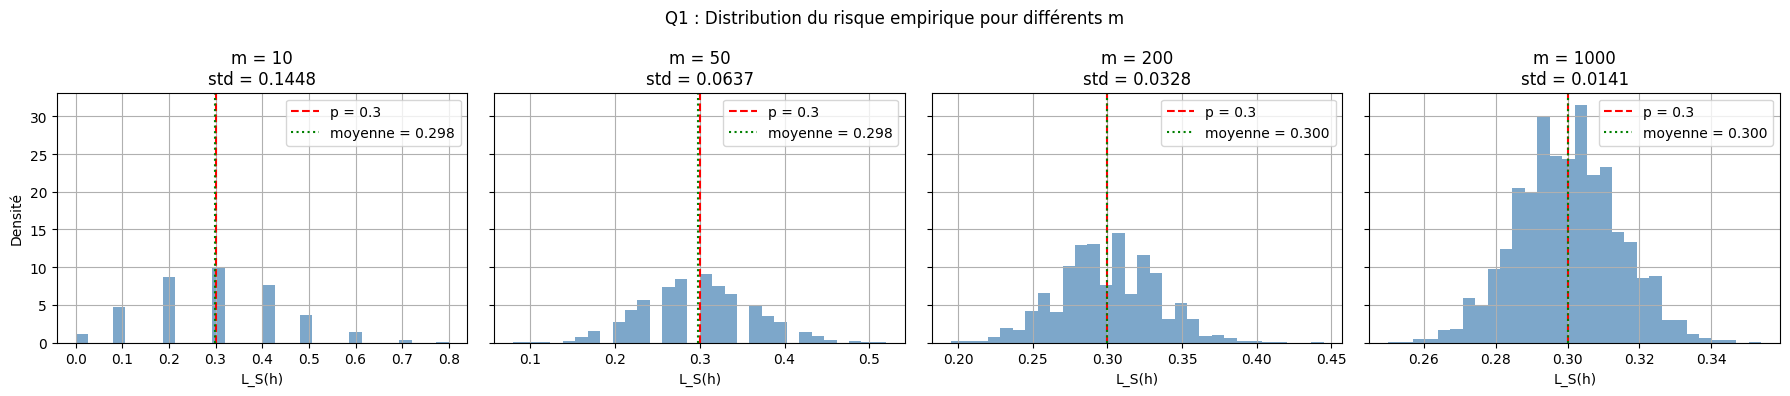

In [27]:
# Q1 : Distribution de L_S(h) pour différents m
# On fixe p_j = 0.3 et on regarde comment L_S varie avec m

p = 0.3                  # vrai risque
ms = [10, 50, 200, 1000] # tailles d'échantillon
n_mc = 5000              # nombre de répétitions Monte-Carlo

fig, axes = plt.subplots(1, len(ms), figsize=(18, 4), sharey=True)
for ax, m in zip(axes, ms):
    # E_j ~ Binomial(m, p), puis L_S = E/m
    E = np.random.binomial(m, p, size=n_mc)
    L_S = E / m
    ax.hist(L_S, bins=30, density=True, alpha=0.7, color='steelblue')
    ax.axvline(p, color='red', linestyle='--', label=f'p = {p}')
    ax.axvline(L_S.mean(), color='green', linestyle=':', label=f'moyenne = {L_S.mean():.3f}')
    ax.set_title(f'm = {m}\nstd = {L_S.std():.4f}')
    ax.set_xlabel('L_S(h)')
    ax.legend()
axes[0].set_ylabel('Densité')
plt.suptitle("Q1 : Distribution du risque empirique pour différents m")
plt.tight_layout()
plt.show()

La moyenne empirique de L_S est proche de p pour tous les m (estimateur sans biais).

L'écart-type de L_S décroît comme 1/√m (visible : plus m grand, histogramme plus étroit).

Cela illustre la loi des grands nombres et la concentration autour du vrai risque.

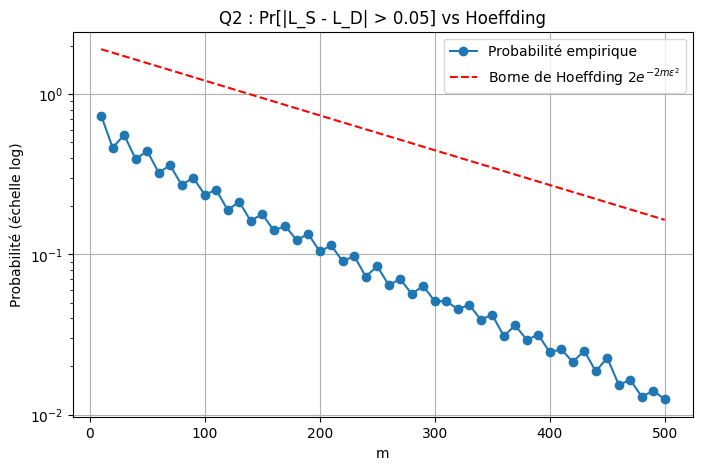

In [28]:
# Q2 : Pr[|L_S - L_D| > eps] vs borne de Hoeffding
p = 0.3
eps = 0.05
n_mc = 20000
ms = np.arange(10, 501, 10)

emp_prob = []
for m in ms:
    E = np.random.binomial(m, p, size=n_mc)
    L_S = E / m
    emp_prob.append(np.mean(np.abs(L_S - p) > eps))
emp_prob = np.array(emp_prob)

# Borne de Hoeffding
hoeff = 2 * np.exp(-2 * ms * eps**2)

plt.figure()
plt.semilogy(ms, emp_prob, 'o-', label='Probabilité empirique')
plt.semilogy(ms, hoeff, 'r--', label='Borne de Hoeffding $2e^{-2m\\epsilon^2}$')
plt.xlabel('m'); plt.ylabel('Probabilité (échelle log)')
plt.title(f"Q2 : Pr[|L_S - L_D| > {eps}] vs Hoeffding")
plt.legend(); plt.show()

La probabilité empirique décroît exponentiellement avec m, comme la borne.

La borne de Hoeffding est toujours au-dessus → elle est conservatrice (suffisante mais pas exacte).

Pour m grand, l'écart entre les deux se creuse (la vraie queue décroît plus vite).

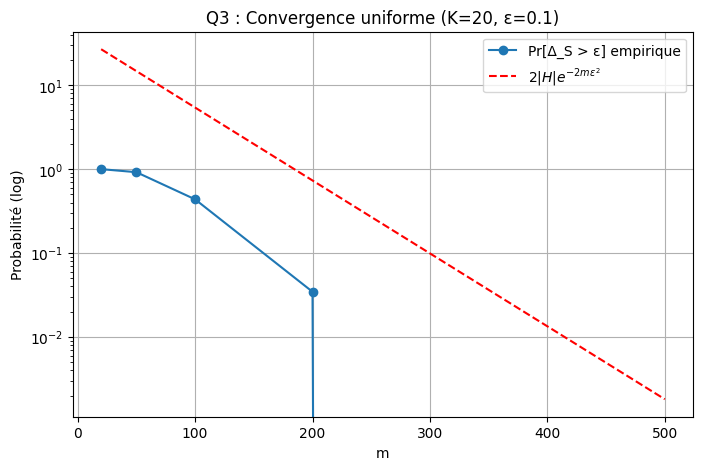

In [29]:
# Q3 : Delta_S = max_h |L_S(h) - L_D(h)|
K = 20
p_list = np.random.uniform(0.1, 0.9, size=K)  # vrais risques fixes
eps = 0.1
n_mc = 5000
ms = [20, 50, 100, 200, 500]

emp_prob = []
for m in ms:
    # Pour chaque répétition, on tire K binomiales
    E = np.random.binomial(m, p_list, size=(n_mc, K))
    L_S = E / m
    delta = np.max(np.abs(L_S - p_list), axis=1)
    emp_prob.append(np.mean(delta > eps))

# Borne uniforme
bound = 2 * K * np.exp(-2 * np.array(ms) * eps**2)

plt.figure()
plt.semilogy(ms, emp_prob, 'o-', label='Pr[Δ_S > ε] empirique')
plt.semilogy(ms, bound, 'r--', label='$2|H|e^{-2m\\epsilon^2}$')
plt.xlabel('m'); plt.ylabel('Probabilité (log)')
plt.title(f"Q3 : Convergence uniforme (K={K}, ε={eps})")
plt.legend(); plt.show()

Le max sur K hypothèses rend l'événement plus probable que pour une seule hypothèse.

La borne uniforme est encore plus conservatrice (facteur |H|).

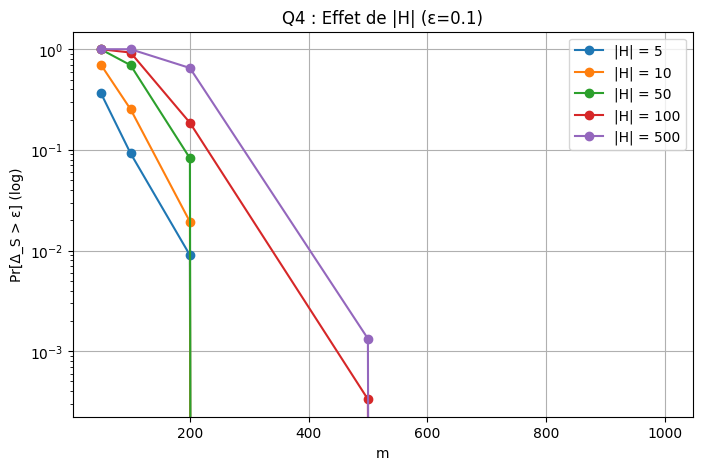

In [30]:
# Q4 : Pr[Δ_S > eps] pour différentes tailles de classe
eps = 0.1
n_mc = 3000
ms = [50, 100, 200, 500, 1000]
Ks = [5, 10, 50, 100, 500]

plt.figure()
for K in Ks:
    p_list = np.random.uniform(0.1, 0.9, size=K)
    probs = []
    for m in ms:
        E = np.random.binomial(m, p_list, size=(n_mc, K))
        L_S = E / m
        delta = np.max(np.abs(L_S - p_list), axis=1)
        probs.append(np.mean(delta > eps))
    plt.semilogy(ms, probs, 'o-', label=f'|H| = {K}')
plt.xlabel('m'); plt.ylabel('Pr[Δ_S > ε] (log)')
plt.title(f"Q4 : Effet de |H| (ε={eps})")
plt.legend(); plt.show()

Plus |H| est grand, plus la probabilité de dépasser ε est élevée pour un m donné.

Autrement dit : plus la classe est grande, plus il faut de données pour garantir la convergence uniforme.

m expérimental minimal : 240
m théorique suffisant  : 380.0


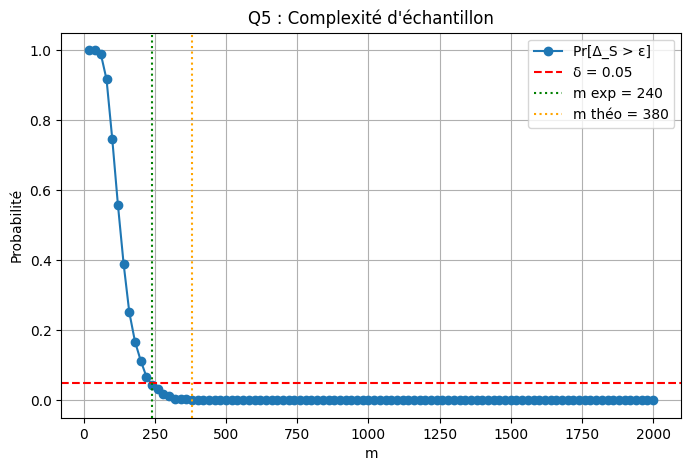

In [31]:
# Q5 : Plus petit m tel que Pr[Δ_S > eps] <= delta
eps, delta = 0.1, 0.05
K = 50
p_list = np.random.uniform(0.1, 0.9, size=K)
n_mc = 5000
ms = np.arange(20, 2001, 20)

probs = []
for m in ms:
    E = np.random.binomial(m, p_list, size=(n_mc, K))
    L_S = E / m
    delta_S = np.max(np.abs(L_S - p_list), axis=1)
    probs.append(np.mean(delta_S > eps))
probs = np.array(probs)

# Plus petit m expérimental
idx = np.where(probs <= delta)[0]
m_exp = ms[idx[0]] if len(idx) > 0 else None

# Borne théorique
m_theo = np.log(2 * K / delta) / (2 * eps**2)

print(f"m expérimental minimal : {m_exp}")
print(f"m théorique suffisant  : {m_theo:.1f}")

plt.figure()
plt.plot(ms, probs, 'o-', label='Pr[Δ_S > ε]')
plt.axhline(delta, color='red', linestyle='--', label=f'δ = {delta}')
plt.axvline(m_exp, color='green', linestyle=':', label=f'm exp = {m_exp}')
plt.axvline(m_theo, color='orange', linestyle=':', label=f'm théo = {m_theo:.0f}')
plt.xlabel('m'); plt.ylabel('Probabilité')
plt.title("Q5 : Complexité d'échantillon")
plt.legend(); plt.show()

Le m théorique est plus grand que le m expérimental → la borne est suffisante mais pas nécessaire.

Elle garantit la convergence uniforme, mais on peut souvent faire mieux en pratique.

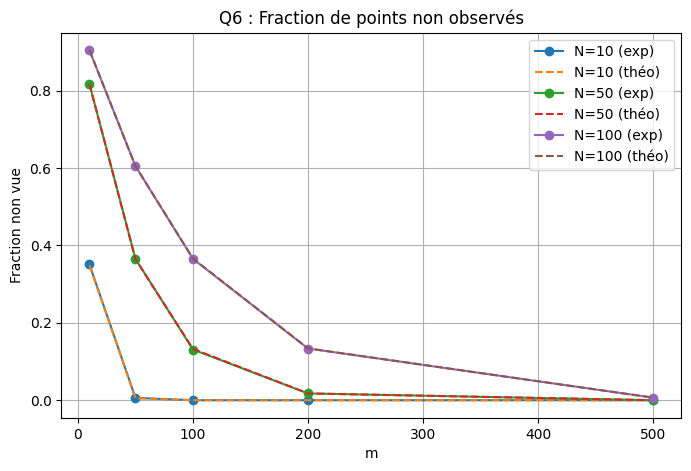

In [32]:
# Q6 : Fraction de points jamais échantillonnés
Ns = [10, 50, 100]
ms = [10, 50, 100, 200, 500]
n_mc = 2000

plt.figure()
for N in Ns:
    fracs = []
    for m in ms:
        counts = []
        for _ in range(n_mc):
            S = np.random.randint(0, N, size=m)
            counts.append(len(set(S)) / N)  # fraction VUE
        fracs.append(1 - np.mean(counts))   # fraction NON vue
    theo = (1 - 1/N) ** np.array(ms)
    plt.plot(ms, fracs, 'o-', label=f'N={N} (exp)')
    plt.plot(ms, theo, '--', label=f'N={N} (théo)')
plt.xlabel('m'); plt.ylabel('Fraction non vue')
plt.title("Q6 : Fraction de points non observés")
plt.legend(); plt.show()

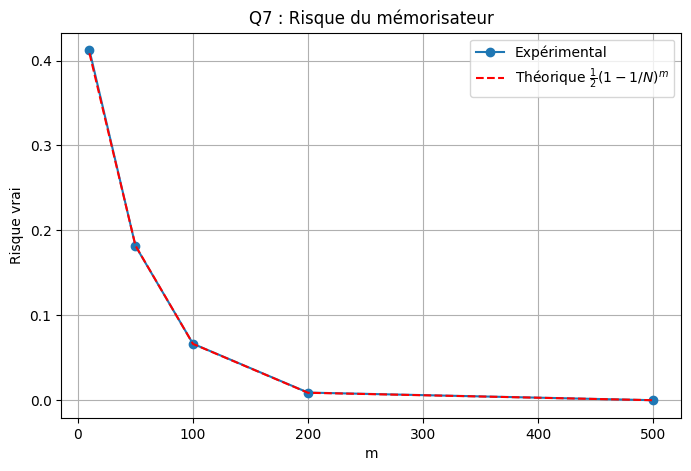

In [33]:
# Q7 : Risque vrai du mémorisateur
N = 50
ms = [10, 50, 100, 200, 500]
n_mc = 2000

risks = []
for m in ms:
    r = []
    for _ in range(n_mc):
        f = np.random.randint(0, 2, size=N)       # cible aléatoire
        S = np.random.randint(0, N, size=m)       # échantillon
        pred = np.zeros(N, dtype=int)             # prédiction par défaut = 0
        pred[S] = f[S]                            # mémorisation
        r.append(np.mean(pred != f))
    risks.append(np.mean(r))

theo = 0.5 * (1 - 1/N) ** np.array(ms)

plt.figure()
plt.plot(ms, risks, 'o-', label='Expérimental')
plt.plot(ms, theo, 'r--', label='Théorique $\\frac{1}{2}(1-1/N)^m$')
plt.xlabel('m'); plt.ylabel('Risque vrai')
plt.title("Q7 : Risque du mémorisateur")
plt.legend(); plt.show()

Le risque décroît avec m mais reste élevé : les points non vus ont une étiquette imprévisible (1/2 d'erreur).

La formule théorique est confirmée : E[L_D] = ½ (1 - 1/N)^m.

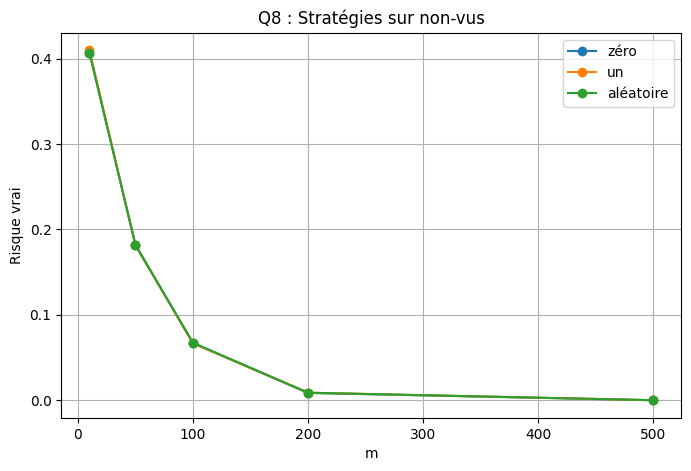

In [34]:
# Q8 : Comparaison de 3 stratégies sur non-vus
N = 50
ms = [10, 50, 100, 200, 500]
n_mc = 2000
strategies = ['zéro', 'un', 'aléatoire']

results = {s: [] for s in strategies}
for m in ms:
    acc = {s: [] for s in strategies}
    for _ in range(n_mc):
        f = np.random.randint(0, 2, size=N)
        S = np.random.randint(0, N, size=m)
        seen = np.zeros(N, dtype=bool); seen[S] = True
        for s in strategies:
            pred = np.zeros(N, dtype=int)
            pred[S] = f[S]
            if s == 'un':
                pred[~seen] = 1
            elif s == 'aléatoire':
                pred[~seen] = np.random.randint(0, 2, size=(~seen).sum())
            acc[s].append(np.mean(pred != f))
    for s in strategies:
        results[s].append(np.mean(acc[s]))

plt.figure()
for s in strategies:
    plt.plot(ms, results[s], 'o-', label=s)
plt.xlabel('m'); plt.ylabel('Risque vrai')
plt.title("Q8 : Stratégies sur non-vus")
plt.legend(); plt.show()

Les trois stratégies ont le même risque en espérance (car les étiquettes non vues sont Bernoulli(1/2)).

Aucune ne domine → No-Free-Lunch : sans hypothèse sur la cible, impossible de battre le hasard sur les points non observés.

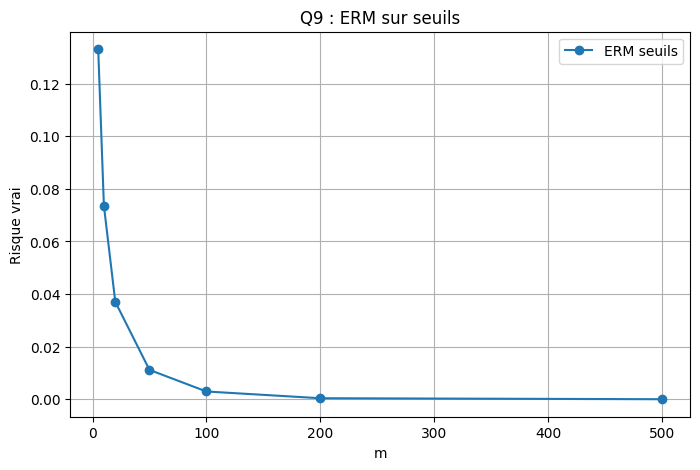

In [35]:
# Q9 : ERM sur classe de seuils
N = 50
ms = [5, 10, 20, 50, 100, 200, 500]
n_mc = 1000

def erm_threshold(S, y, N):
    """Cherche le seuil t qui minimise l'erreur sur (S, y)."""
    best_t, best_err = 0, float('inf')
    for t in range(0, N):  # t = 0 => prédit toujours 1 ; t = N-1 => seuil
        pred = (S > t).astype(int)
        err = np.mean(pred != y)
        if err < best_err:
            best_err, best_t = err, t
    return best_t

risks = []
for m in ms:
    r = []
    for _ in range(n_mc):
        theta = np.random.randint(1, N)
        f = lambda x: (x > theta).astype(int)
        S = np.random.randint(0, N, size=m)
        y = f(S)
        t_hat = erm_threshold(S, y, N)
        # Risque sur tout le domaine
        x_all = np.arange(N)
        r.append(np.mean((x_all > t_hat).astype(int) != f(x_all)))
    risks.append(np.mean(r))

plt.figure()
plt.plot(ms, risks, 'o-', label='ERM seuils')
plt.xlabel('m'); plt.ylabel('Risque vrai')
plt.title("Q9 : ERM sur seuils")
plt.legend(); plt.show()

Le risque décroît beaucoup plus vite que dans la Partie II.

Une fois qu'on a vu des points de part et d'autre du seuil, l'ERM identifie bien θ.

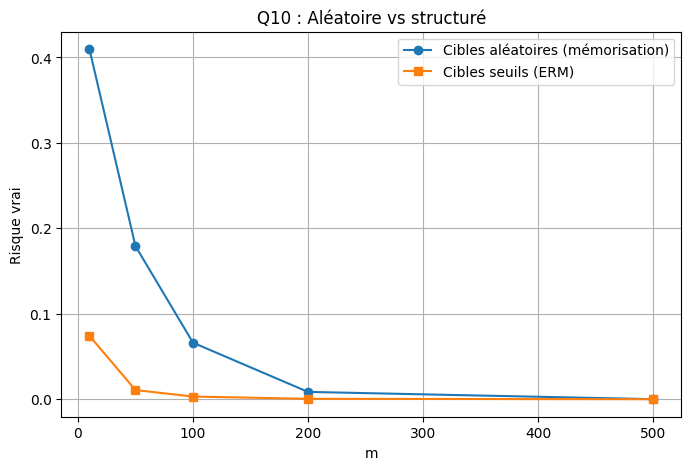

In [36]:
# Q10 : Comparaison directe
# (réutilise les résultats de Q7 et Q9)

# Cibles aléatoires (Q7)
N = 50
ms = [10, 50, 100, 200, 500]
n_mc = 1000
risks_rand = []
for m in ms:
    r = []
    for _ in range(n_mc):
        f = np.random.randint(0, 2, size=N)
        S = np.random.randint(0, N, size=m)
        pred = np.zeros(N, dtype=int); pred[S] = f[S]
        r.append(np.mean(pred != f))
    risks_rand.append(np.mean(r))

# Cibles seuils (Q9)
risks_thresh = []
for m in ms:
    r = []
    for _ in range(n_mc):
        theta = np.random.randint(1, N)
        f = lambda x: (x > theta).astype(int)
        S = np.random.randint(0, N, size=m)
        y = f(S)
        t_hat = erm_threshold(S, y, N)
        x_all = np.arange(N)
        r.append(np.mean((x_all > t_hat).astype(int) != f(x_all)))
    risks_thresh.append(np.mean(r))

plt.figure()
plt.plot(ms, risks_rand, 'o-', label='Cibles aléatoires (mémorisation)')
plt.plot(ms, risks_thresh, 's-', label='Cibles seuils (ERM)')
plt.xlabel('m'); plt.ylabel('Risque vrai')
plt.title("Q10 : Aléatoire vs structuré")
plt.legend(); plt.show()

Avec cibles aléatoires, le risque plafonne (impossible de généraliser).

Avec cibles seuils et ERM sur seuils, le risque tend vers 0.

Rôle clé : l'hypothèse que la cible appartient à la famille des seuils (biais inductif correct) permet d'extrapoler aux points non vus.

## Q11 — Conclusion générale

1. **Concentration de L_S autour de L_D** : par la loi des grands nombres et Hoeffding,
   L_S(h) → L_D(h) quand m → ∞, avec une vitesse exponentielle.

2. **Convergence uniforme** : il ne suffit pas que chaque h converge, il faut que
   TOUTES convergent simultanément (le max sur H doit être petit).

3. **Effet de |H|** : plus |H| est grand, plus la borne 2|H|e^{-2mε²} est grande,
   donc plus il faut de données pour garantir la convergence uniforme.

4. **Bornes conservatrices** : Hoeffding et la borne uniforme sont des garanties
   suffisantes, mais souvent pessimistes (elles majorent la vraie probabilité).

5. **No-Free-Lunch** : avec des cibles complètement aléatoires, les étiquettes des
   points non vus sont imprévisibles (Bernoulli(1/2)). Aucune stratégie ne peut
   faire mieux que 1/2 d'erreur sur ces points.

6. **Biais inductif** : en restreignant cible et hypothèses aux seuils, on introduit
   une connaissance a priori. L'ERM peut alors généraliser aux points non vus,
   car la structure de la cible est capturée par la classe d'hypothèses.

**Message final** : l'apprentissage n'est possible que si l'on fait des hypothèses
sur la nature de la cible. La convergence uniforme quantifie le prix à payer
(en données) pour garantir que l'ERM généralise.